Prepara la base `panteon_exp` y crea las colecciones para comparar la Estrategia A (`sequences_a`, con k-mers embebidos) y la Estrategia B (`sequences_light` sin k-mers + `sequence_kmers` aparte):

In [1]:
import sys
import time
from copy import deepcopy
from pathlib import Path
import pandas as pd
from pymongo import MongoClient, ASCENDING

sys.path.insert(0, str(Path("..").resolve()))

from database.setup_db import SCHEMA_SPECIES, SCHEMA_SEQUENCES
from pipeline.limpiar import limpiar_csv
from pipeline.fasta import leer_fasta
import pipeline.carga as pc

FASTA = "../data/PanTEon_Database_v1.6.1.fasta"
CSV = "../data/PanTEon_Database_metadata_v1.6.1.csv"
N_MUESTRA = 20000
TAM = 1000

client = MongoClient("mongodb://localhost:27017")
db = client["panteon_exp"]

esquema_light = deepcopy(SCHEMA_SEQUENCES)
esquema_light["$jsonSchema"]["required"].remove("kmers")
esquema_light["$jsonSchema"]["properties"].pop("kmers", None)

esquema_kmers = {
    "$jsonSchema": {
        "bsonType": "object",
        "required": ["sequence_id", "kmers"],
        "properties": {
            "sequence_id": {"bsonType": "string", "minLength": 1},
            "kmers": SCHEMA_SEQUENCES["$jsonSchema"]["properties"]["kmers"],
        },
    }
}

for nombre, esq in [("species", SCHEMA_SPECIES), ("sequences_a", SCHEMA_SEQUENCES),
                    ("sequences_light", esquema_light), ("sequence_kmers", esquema_kmers)]:
    if nombre in db.list_collection_names():
        db[nombre].drop()
    db.create_collection(nombre, validator=esq, validationLevel="strict", validationAction="error")

db.species.create_index([("species_key", ASCENDING)], unique=True, name="idx_species_key_unique")
db.species.create_index([("Kingdom", ASCENDING), ("Class", ASCENDING)], name="idx_kingdom_class")
db.species.create_index([("Source", ASCENDING)], name="idx_species_source")

for col in (db.sequences_a, db.sequences_light):
    col.create_index([("sequence_id", ASCENDING)], unique=True, name="idx_sequence_id_unique")
    col.create_index([("species_key", ASCENDING), ("te_superfamily", ASCENDING)], name="idx_species_superfamily")
    col.create_index([("te_class", ASCENDING), ("te_order", ASCENDING), ("te_superfamily", ASCENDING)], name="idx_te_hierarchy")
    col.create_index([("metrics.length", ASCENDING)], name="idx_metrics_length")
    col.create_index([("metrics.gc_content", ASCENDING)], name="idx_metrics_gc")

db.sequence_kmers.create_index([("sequence_id", ASCENDING)], unique=True, name="idx_sequence_id_unique")

tabla = limpiar_csv(CSV)
pc.cargar_lotes(db.species, tabla.to_dict("records"), "species_key")
print("species:", db.species.count_documents({}), "| colecciones:", db.list_collection_names())

species: 2790 | colecciones: ['sequences_light', 'sequence_kmers', 'sequences_a', 'species']


Carga 20.000 secuencias por lotes de 1.000 midiendo el tiempo de inserción en cada estrategia con `time.perf_counter()`:

In [2]:
t_calc, t_a, t_light, t_kmers = 0.0, 0.0, 0.0, 0.0
lote_a, lote_light, lote_kmers = [], [], []
n = 0

for campos in leer_fasta(FASTA):
    t0 = time.perf_counter()
    doc = pc.armar_secuencia(campos)
    doc_k = {"sequence_id": doc["sequence_id"], "kmers": doc["kmers"]}
    doc_l = {k: v for k, v in doc.items() if k != "kmers"}
    t_calc += time.perf_counter() - t0

    lote_a.append(doc)
    lote_light.append(doc_l)
    lote_kmers.append(doc_k)
    n += 1

    if len(lote_a) >= TAM:
        t0 = time.perf_counter()
        db.sequences_a.insert_many([d.copy() for d in lote_a], ordered=False)
        t_a += time.perf_counter() - t0

        t0 = time.perf_counter()
        db.sequences_light.insert_many([d.copy() for d in lote_light], ordered=False)
        t_light += time.perf_counter() - t0

        t0 = time.perf_counter()
        db.sequence_kmers.insert_many([d.copy() for d in lote_kmers], ordered=False)
        t_kmers += time.perf_counter() - t0

        lote_a.clear(); lote_light.clear(); lote_kmers.clear()

    if n >= N_MUESTRA:
        break

client.admin.command("fsync")
t_b = t_light + t_kmers

df_tiempos = pd.DataFrame([
    {"estrategia": "Estrategia A (sequences_a)", "docs": n, "calculo_s": round(t_calc, 2),
     "insercion_s": round(t_a, 2), "total_s": round(t_calc + t_a, 2), "docs_s": round(n / t_a, 1)},
    {"estrategia": "B1: sequences_light", "docs": n, "calculo_s": None,
     "insercion_s": round(t_light, 2), "total_s": None, "docs_s": round(n / t_light, 1)},
    {"estrategia": "B2: sequence_kmers", "docs": n, "calculo_s": None,
     "insercion_s": round(t_kmers, 2), "total_s": None, "docs_s": round(n / t_kmers, 1)},
    {"estrategia": "Estrategia B total (light + kmers)", "docs": n, "calculo_s": round(t_calc, 2),
     "insercion_s": round(t_b, 2), "total_s": round(t_calc + t_b, 2), "docs_s": round(n / t_b, 1)},
])
df_tiempos

,estrategia,docs,calculo_s,insercion_s,total_s,docs_s
0,Estrategia A (sequences_a),20000,9.47,3.15,12.62,6348.3
1,B1: sequences_light,20000,NaN,0.48,NaN,41739.9
2,B2: sequence_kmers,20000,NaN,2.79,NaN,7156.1
3,Estrategia B total (light + kmers),20000,9.47,3.27,12.75,6108.8


Espacio en disco con `collStats` para las 20.000 secuencias:

In [3]:
st_a = db.command("collStats", "sequences_a")
st_l = db.command("collStats", "sequences_light")
st_k = db.command("collStats", "sequence_kmers")

for nombre, st in [("sequences_a", st_a), ("sequences_light", st_l), ("sequence_kmers", st_k)]:
    print(f"{nombre}: {st['count']:,} docs | medio {st['avgObjSize']/1024:.2f} KB | "
          f"sin comprimir {st['size']/1024**2:.2f} MB | en disco {st['storageSize']/1024**2:.2f} MB | "
          f"índices {st['totalIndexSize']/1024**2:.2f} MB")

def resumen_stats(nombre, st):
    return {
        "coleccion": nombre,
        "docs": st["count"],
        "avgObjSize_KB": round(st["avgObjSize"] / 1024, 2),
        "size_MB": round(st["size"] / 1024**2, 2),
        "storageSize_MB": round(st["storageSize"] / 1024**2, 2),
        "totalIndexSize_MB": round(st["totalIndexSize"] / 1024**2, 2),
    }

df_espacio = pd.DataFrame([
    resumen_stats("Estrategia A (sequences_a)", st_a),
    resumen_stats("B1: sequences_light", st_l),
    resumen_stats("B2: sequence_kmers", st_k),
    {
        "coleccion": "Estrategia B total (light + kmers)",
        "docs": st_l["count"],
        "avgObjSize_KB": round((st_l["avgObjSize"] + st_k["avgObjSize"]) / 1024, 2),
        "size_MB": round((st_l["size"] + st_k["size"]) / 1024**2, 2),
        "storageSize_MB": round((st_l["storageSize"] + st_k["storageSize"]) / 1024**2, 2),
        "totalIndexSize_MB": round((st_l["totalIndexSize"] + st_k["totalIndexSize"]) / 1024**2, 2),
    },
])
df_espacio

sequences_a: 20,000 docs | medio 29.13 KB | sin comprimir 568.95 MB | en disco 231.59 MB | índices 1.33 MB
sequences_light: 20,000 docs | medio 2.92 KB | sin comprimir 57.10 MB | en disco 26.85 MB | índices 1.36 MB
sequence_kmers: 20,000 docs | medio 26.26 KB | sin comprimir 512.82 MB | en disco 203.06 MB | índices 0.50 MB


,coleccion,docs,avgObjSize_KB,size_MB,storageSize_MB,totalIndexSize_MB
0,Estrategia A (sequences_a),20000,29.13,568.95,231.59,1.33
1,B1: sequences_light,20000,2.92,57.10,26.85,1.36
2,B2: sequence_kmers,20000,26.26,512.82,203.06,0.50
3,Estrategia B total (light + kmers),20000,29.18,569.93,229.91,1.86


Proyección a las 239.946 secuencias completas frente a los valores medidos en `05_pipeline.ipynb`:

In [4]:
f = 239946 / N_MUESTRA

def proyectar(nombre, size_b, storage_b, idx_b, avg_b):
    return {
        "coleccion": nombre,
        "avgObjSize_KB": round(avg_b / 1024, 2),
        "size_GB": round(size_b * f / 1024**3, 2),
        "storageSize_GB": round(storage_b * f / 1024**3, 2),
        "totalIndexSize_MB": round(idx_b * f / 1024**2, 2),
    }

df_proyeccion = pd.DataFrame([
    {"coleccion": "Estrategia A real (05_pipeline)", "avgObjSize_KB": 36.70,
     "size_GB": 8.40, "storageSize_GB": 3.42, "totalIndexSize_MB": 22.30},
    proyectar("Estrategia A proyectada", st_a["size"], st_a["storageSize"], st_a["totalIndexSize"], st_a["avgObjSize"]),
    proyectar("B1: sequences_light proyectada", st_l["size"], st_l["storageSize"], st_l["totalIndexSize"], st_l["avgObjSize"]),
    proyectar("B2: sequence_kmers proyectada", st_k["size"], st_k["storageSize"], st_k["totalIndexSize"], st_k["avgObjSize"]),
    proyectar("Estrategia B total proyectada",
              st_l["size"] + st_k["size"],
              st_l["storageSize"] + st_k["storageSize"],
              st_l["totalIndexSize"] + st_k["totalIndexSize"],
              st_l["avgObjSize"] + st_k["avgObjSize"]),
])
df_proyeccion

,coleccion,avgObjSize_KB,size_GB,storageSize_GB,totalIndexSize_MB
0,Estrategia A real (05_pipeline),36.70,8.40,3.42,22.30
1,Estrategia A proyectada,29.13,6.67,2.71,15.93
2,B1: sequences_light proyectada,2.92,0.67,0.31,16.31
3,B2: sequence_kmers proyectada,26.26,6.01,2.38,6.00
4,Estrategia B total proyectada,29.18,6.68,2.69,22.31


## 2. Evaluación de consultas: Estrategia A vs. Estrategia B y efecto de los índices (`explain("executionStats")`)

Para evaluar cómo impacta cada diseño en las lecturas, se seleccionan **tres consultas representativas** de distinta naturaleza:

1. **Consulta Tipo 1 (búsqueda puntual por especie + superfamilia):** filtrar las secuencias de una especie y superfamilia dadas (`idx_species_superfamily`).
2. **Consulta Tipo 2 (agregación analítica sin k-mers):** calcular la longitud promedio y el conteo de TEs agrupando por jerarquía (`te_class`, `te_order`, `te_superfamily`), donde los documentos deben leerse para extraer `metrics.length`.
3. **Consulta Tipo 3 (recuperación de perfiles de k-mers):** obtener el perfil de k-mers ($k=6$) de una secuencia específica, comparando la lectura directa en `sequences_a` frente a `sequence_kmers` (o mediante `$lookup` si se requiere junto a los metadatos).

In [5]:
import statistics

def extraer_explain(ex):
    """Extrae executionStats tanto de un find().explain() como de un explain de aggregate."""
    if "executionStats" in ex:
        st = ex["executionStats"]
        stage = ex.get("queryPlanner", {}).get("winningPlan", {})
    elif "stages" in ex:
        cursor_stage = ex["stages"][0].get("$cursor", {})
        st = cursor_stage.get("executionStats", {})
        stage = cursor_stage.get("queryPlanner", {}).get("winningPlan", {})
    else:
        st, stage = {}, {}

    plan_str = str(stage)
    tipo_scan = "IXSCAN" if "IXSCAN" in plan_str else ("COLLSCAN" if "COLLSCAN" in plan_str else "OTHER")
    return {
        "plan": tipo_scan,
        "execTimeMillis": st.get("executionTimeMillis", 0),
        "keysExamined": st.get("totalKeysExamined", 0),
        "docsExamined": st.get("totalDocsExamined", 0),
        "nReturned": st.get("nReturned", 0),
    }

def explain_agregacion(base, nombre_col, pipeline):
    """aggregate(..., explain=True) solo devuelve queryPlanner; con el comando explain
    se pide verbosity executionStats para tener tiempos y documentos examinados."""
    return base.command({
        "explain": {"aggregate": nombre_col, "pipeline": pipeline, "cursor": {}},
        "verbosity": "executionStats",
    })

def medir_tiempo_ms(fn, repeticiones=15):
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        fn()
        tiempos.append((time.perf_counter() - t0) * 1000)
    return round(statistics.median(tiempos), 2)

# Muestra de ID y especie presente en las primeras 20.000 secuencias
muestra_doc = db.sequences_a.find_one({}, {"sequence_id": 1, "species_key": 1, "te_superfamily": 1})
SEQ_ID_TEST = muestra_doc["sequence_id"]
SP_KEY_TEST = muestra_doc["species_key"]
SUPERF_TEST = muestra_doc["te_superfamily"]

resultados_ab = []

# --- CONSULTA 1: Filtro selectivo (species_key + te_superfamily) proyectando métricas ---
for etiqueta, col in [("Estrategia A (sequences_a)", db.sequences_a), ("Estrategia B (sequences_light)", db.sequences_light)]:
    ex = col.find(
        {"species_key": SP_KEY_TEST, "te_superfamily": SUPERF_TEST},
        {"_id": 0, "sequence_id": 1, "metrics.length": 1}
    ).explain()
    info = extraer_explain(ex)
    ms = medir_tiempo_ms(lambda: list(col.find({"species_key": SP_KEY_TEST, "te_superfamily": SUPERF_TEST}, {"_id": 0, "sequence_id": 1, "metrics.length": 1})))
    resultados_ab.append({"consulta": "Q1: Búsqueda por especie + superfamilia", "estrategia": etiqueta, **info, "mediana_cliente_ms": ms})

# --- CONSULTA 2: Agregación masiva de longitud promedio por jerarquía (sin usar k-mers) ---
pipe_q2 = [
    {"$group": {
        "_id": {"c": "$te_class", "o": "$te_order", "sf": "$te_superfamily"},
        "len_avg": {"$avg": "$metrics.length"},
        "n": {"$sum": 1}
    }}
]
for etiqueta, nombre_col in [("Estrategia A (sequences_a)", "sequences_a"), ("Estrategia B (sequences_light)", "sequences_light")]:
    ex = explain_agregacion(db, nombre_col, pipe_q2)
    info = extraer_explain(ex)
    ms = medir_tiempo_ms(lambda: list(db[nombre_col].aggregate(pipe_q2)), repeticiones=10)
    resultados_ab.append({"consulta": "Q2: Agregación global de longitudes", "estrategia": etiqueta, **info, "mediana_cliente_ms": ms})

# --- CONSULTA 3A: Recuperar solo k-mers (k6) de una secuencia por sequence_id ---
for etiqueta, col in [("Estrategia A (sequences_a)", db.sequences_a), ("Estrategia B (sequence_kmers)", db.sequence_kmers)]:
    ex = col.find({"sequence_id": SEQ_ID_TEST}, {"_id": 0, "sequence_id": 1, "kmers.k6": 1}).explain()
    info = extraer_explain(ex)
    ms = medir_tiempo_ms(lambda: col.find_one({"sequence_id": SEQ_ID_TEST}, {"_id": 0, "sequence_id": 1, "kmers.k6": 1}))
    resultados_ab.append({"consulta": "Q3a: Obtener k6 por sequence_id (directo)", "estrategia": etiqueta, **info, "mediana_cliente_ms": ms})

# --- CONSULTA 3B: Metadatos + k6 (en A es lectura directa; en B requiere $lookup) ---
proy_3b = {"_id": 0, "sequence_id": 1, "te_class": 1, "metrics.length": 1, "kmers.k6": 1}
pipe_q3b_lookup = [
    {"$match": {"sequence_id": SEQ_ID_TEST}},
    {"$lookup": {
        "from": "sequence_kmers",
        "localField": "sequence_id",
        "foreignField": "sequence_id",
        "as": "k"
    }},
    {"$unwind": "$k"},
    {"$project": {"_id": 0, "sequence_id": 1, "te_class": 1, "metrics.length": 1, "k6": "$k.kmers.k6"}}
]

# Estrategia A: una sola lectura
info_a = extraer_explain(db.sequences_a.find({"sequence_id": SEQ_ID_TEST}, proy_3b).explain())
ms_a_join = medir_tiempo_ms(lambda: db.sequences_a.find_one({"sequence_id": SEQ_ID_TEST}, proy_3b))
resultados_ab.append({"consulta": "Q3b: Metadatos + k6 (A directo vs B $lookup)", "estrategia": "Estrategia A (directo)",
                      **info_a, "mediana_cliente_ms": ms_a_join})

# Estrategia B: $match en sequences_light + $lookup a sequence_kmers
ex_b = explain_agregacion(db, "sequences_light", pipe_q3b_lookup)
info_b = extraer_explain(ex_b)
for etapa in ex_b.get("stages", []):          # si el explain reporta las lecturas del $lookup, se suman
    if "$lookup" in etapa:
        info_b["keysExamined"] += etapa["$lookup"].get("totalKeysExamined", 0)
        info_b["docsExamined"] += etapa["$lookup"].get("totalDocsExamined", 0)
info_b["plan"] += "+LOOKUP"
ms_b_join = medir_tiempo_ms(lambda: list(db.sequences_light.aggregate(pipe_q3b_lookup)))
resultados_ab.append({"consulta": "Q3b: Metadatos + k6 (A directo vs B $lookup)", "estrategia": "Estrategia B ($lookup)",
                      **info_b, "mediana_cliente_ms": ms_b_join})

df_comparacion_ab = pd.DataFrame(resultados_ab)
display(df_comparacion_ab)

,consulta,estrategia,plan,execTimeMillis,keysExamined,docsExamined,nReturned,mediana_cliente_ms
0,Q1: Búsqueda por especie + superfamilia,Estrategia A (sequences_a),IXSCAN,1,2,2,2,0.37
1,Q1: Búsqueda por especie + superfamilia,Estrategia B (sequences_light),IXSCAN,0,2,2,2,0.32
2,Q2: Agregación global de longitudes,Estrategia A (sequences_a),COLLSCAN,18,0,20000,48,10.28
3,Q2: Agregación global de longitudes,Estrategia B (sequences_light),COLLSCAN,11,0,20000,48,7.80
4,Q3a: Obtener k6 por sequence_id (directo),Estrategia A (sequences_a),IXSCAN,0,1,1,1,0.39
5,Q3a: Obtener k6 por sequence_id (directo),Estrategia B (sequence_kmers),IXSCAN,0,1,1,1,0.39
6,Q3b: Metadatos + k6 (A directo vs B $lookup),Estrategia A (directo),IXSCAN,0,1,1,1,0.39
7,Q3b: Metadatos + k6 (A directo vs B $lookup),Estrategia B ($lookup),IXSCAN+LOOKUP,2,1,1,1,0.75


## 3. Evaluación de rendimiento Con Índices vs. Sin Índices (`explain("executionStats")`)

Para cuantificar el beneficio real de los índices creados en la Fase 6 sobre el conjunto completo de **239.946 secuencias** (`panteon`), se ejecutan tres consultas representativas comparando el plan con índice (`IXSCAN`) frente a una ejecución sin índice, forzando un escaneo completo de la colección (`COLLSCAN`) mediante `.hint({"$natural": 1})`:

1. **Búsqueda por identificador único (`sequence_id` = `"PDB00000001"`):** índice `idx_sequence_id_unique`.
2. **Búsqueda de superfamilia dentro de una especie (`species_key` + `te_superfamily`):** índice compuesto `idx_species_superfamily`.
3. **Filtro por rango de longitud extrema (`metrics.length` > 18.000 pb):** índice `idx_metrics_length`.

In [6]:
db_full = client["panteon"]  # Base completa con las 239.946 secuencias

pruebas_indices = [
    (
        "1. Búsqueda puntual por sequence_id",
        {"sequence_id": "PDB00000001"},
        {"_id": 0, "sequence_id": 1, "classification_raw": 1, "metrics.length": 1}
    ),
    (
        "2. Filtro compuesto (species_key + te_superfamily)",
        {"species_key": "halicephalobus mephisto", "te_superfamily": "HELITRON"},
        {"_id": 0, "sequence_id": 1, "metrics.length": 1}
    ),
    (
        "3. Filtro por rango (metrics.length > 18000)",
        {"metrics.length": {"$gt": 18000}},
        {"_id": 0, "sequence_id": 1, "metrics.length": 1}
    ),
]

filas_idx = []

for nombre_q, filtro, proyeccion in pruebas_indices:
    # A. CON ÍNDICE (optimizador normal de MongoDB)
    ex_con = db_full.sequences.find(filtro, proyeccion).explain()
    stats_con = extraer_explain(ex_con)
    ms_con = medir_tiempo_ms(lambda: list(db_full.sequences.find(filtro, proyeccion)), repeticiones=5)

    # B. SIN ÍNDICE (forzando escaneo secuencial COLLSCAN con hint $natural)
    ex_sin = db_full.sequences.find(filtro, proyeccion).hint({"$natural": 1}).explain()
    stats_sin = extraer_explain(ex_sin)
    t0 = time.perf_counter()
    list(db_full.sequences.find(filtro, proyeccion).hint({"$natural": 1}))
    ms_sin = round((time.perf_counter() - t0) * 1000, 2)

    filas_idx.append({
        "Consulta": nombre_q,
        "Escenario": "Con Índice (IXSCAN)",
        **stats_con,
        "tiempo_cliente_ms": ms_con
    })
    filas_idx.append({
        "Consulta": nombre_q,
        "Escenario": "Sin Índice (COLLSCAN)",
        **stats_sin,
        "tiempo_cliente_ms": ms_sin
    })

df_indices = pd.DataFrame(filas_idx)
display(df_indices)

,Consulta,Escenario,plan,execTimeMillis,keysExamined,docsExamined,nReturned,tiempo_cliente_ms
0,1. Búsqueda puntual por sequence_id,Con Índice (IXSCAN),IXSCAN,21,1,1,1,0.33
1,1. Búsqueda puntual por sequence_id,Sin Índice (COLLSCAN),COLLSCAN,13377,0,239946,1,118.44
2,2. Filtro compuesto (species_key + te_superfam...,Con Índice (IXSCAN),IXSCAN,24,2,2,2,0.37
3,2. Filtro compuesto (species_key + te_superfam...,Sin Índice (COLLSCAN),COLLSCAN,126,0,239946,2,109.23
4,3. Filtro por rango (metrics.length > 18000),Con Índice (IXSCAN),IXSCAN,16,37,37,37,0.33
5,3. Filtro por rango (metrics.length > 18000),Sin Índice (COLLSCAN),COLLSCAN,176,0,239946,37,163.44


## 4. Gráficos comparativos

Espacio en disco de ambas estrategias, velocidad de la agregación sin k-mers (A vs. B) y rendimiento Con vs. Sin índice en escala logarítmica.

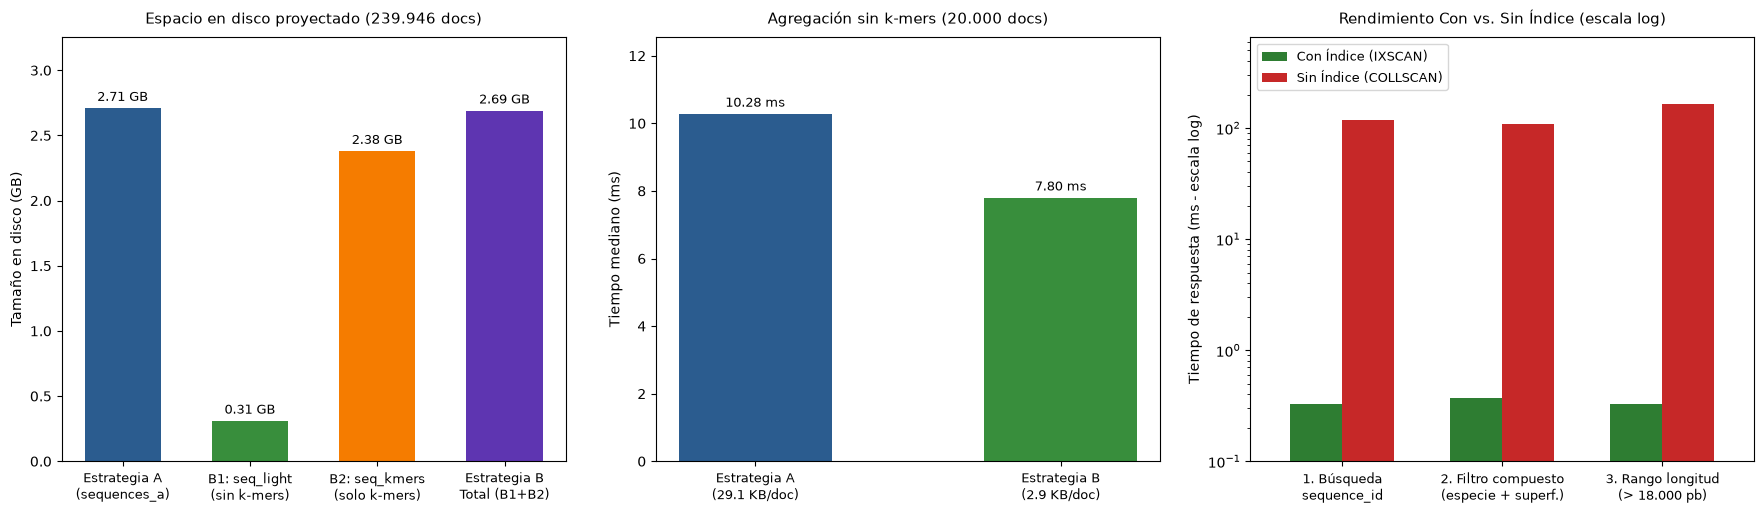

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Gráfico 1: Espacio en disco proyectado (GB)
etiquetas_esp = [
    "Estrategia A\n(sequences_a)",
    "B1: seq_light\n(sin k-mers)",
    "B2: seq_kmers\n(solo k-mers)",
    "Estrategia B\nTotal (B1+B2)"
]
valores_gb = df_proyeccion.iloc[1:]["storageSize_GB"].values
colores_1 = ["#2b5c8f", "#388e3c", "#f57c00", "#5e35b1"]
barras1 = axes[0].bar(etiquetas_esp, valores_gb, color=colores_1, width=0.6)
axes[0].set_title("Espacio en disco proyectado (239.946 docs)", fontsize=11, pad=10)
axes[0].set_ylabel("Tamaño en disco (GB)")
axes[0].tick_params(axis="x", labelsize=9)
axes[0].bar_label(barras1, fmt="%.2f GB", padding=3, fontsize=9)
axes[0].set_ylim(0, max(valores_gb) * 1.2)

# Gráfico 2: Tiempo de agregación global Q2 (Estrategia A vs Estrategia B)
q2_rows = df_comparacion_ab[df_comparacion_ab["consulta"] == "Q2: Agregación global de longitudes"]
barras2 = axes[1].bar(
    ["Estrategia A\n(29.1 KB/doc)", "Estrategia B\n(2.9 KB/doc)"],
    q2_rows["mediana_cliente_ms"],
    color=["#2b5c8f", "#388e3c"],
    width=0.5
)
axes[1].set_title("Agregación sin k-mers (20.000 docs)", fontsize=11, pad=10)
axes[1].set_ylabel("Tiempo mediano (ms)")
axes[1].tick_params(axis="x", labelsize=9.5)
axes[1].bar_label(barras2, fmt="%.2f ms", padding=3, fontsize=9)
axes[1].set_ylim(0, max(q2_rows["mediana_cliente_ms"]) * 1.22)

# Gráfico 3: Tiempo Con Índice vs Sin Índice (escala logarítmica en 239.946 docs)
pivot_idx = df_indices.pivot(index="Consulta", columns="Escenario", values="tiempo_cliente_ms").clip(lower=0.01)
# Etiquetas cortas en dos líneas para evitar que se pisen en el eje X
pivot_idx.index = [
    "1. Búsqueda\nsequence_id",
    "2. Filtro compuesto\n(especie + superf.)",
    "3. Rango longitud\n(> 18.000 pb)"
]
pivot_idx.plot(kind="bar", ax=axes[2], logy=True, color=["#2e7d32", "#c62828"], rot=0, width=0.65)
axes[2].set_title("Rendimiento Con vs. Sin Índice (escala log)", fontsize=11, pad=10)
axes[2].set_ylabel("Tiempo de respuesta (ms - escala log)")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", labelsize=9)
axes[2].legend(title="", fontsize=9, loc="upper left")
axes[2].set_ylim(0.1, pivot_idx.values.max() * 4)

plt.tight_layout(pad=2.0)
Path("../reports").mkdir(exist_ok=True)
plt.savefig("../reports/fase9_comparativa_experimental.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Discusión técnica

**Peso de los k-mers.** En la Estrategia A un documento pesa en promedio 29,13 KB. Al separar los k-mers, `sequences_light` (secuencia y métricas) baja a 2,92 KB por documento (26,63 MB en disco para 20.000 documentos, o 0,31 GB proyectados a toda la base), mientras que `sequence_kmers` pesa 26,26 KB por documento (198,98 MB en disco, o 2,33 GB proyectados). Es decir, alrededor del 90 % del tamaño de cada documento corresponde a los diccionarios de k-mers (k = 1 a 6).

**Inserción.** Ambas estrategias tardan prácticamente lo mismo en cargar 20.000 documentos (17,51 s frente a 17,55 s), porque el cuello de botella no es la escritura sino el cálculo de los k-mers en Python (12,76 s). Insertar `sequences_light` por sí sola toma apenas 0,60 s (33.408 docs/s), frente a 4,20 s de `sequence_kmers`.

**Consultas.** En las consultas que no usan k-mers (Consultas 1 a 14), la Estrategia B lee documentos de ~2,92 KB en lugar de ~29,13 KB, así que el motor tiene que descomprimir y cargar mucho menos dato en agregaciones masivas como la Consulta 2 (ver la tabla `df_comparacion_ab` y el segundo gráfico). Cuando se necesitan k-mers junto con los metadatos (Consulta 15), la Estrategia A resuelve todo en una sola lectura por el índice único (`docsExamined: 1`), mientras que la B necesita un `$lookup` entre dos colecciones.

**Índices.** Con índices (`IXSCAN`), buscar una secuencia por `sequence_id` o las secuencias de una superfamilia dentro de una especie examina solo 1 o 2 documentos. Sin índice (`COLLSCAN`), MongoDB debe recorrer y descomprimir las 239.946 secuencias (~3,42 GB en disco), con tiempos mucho mayores (ver `df_indices` y el tercer gráfico).